In [19]:
import numpy as np
import cv2 as cv
import cv2
from matplotlib import pyplot as plt

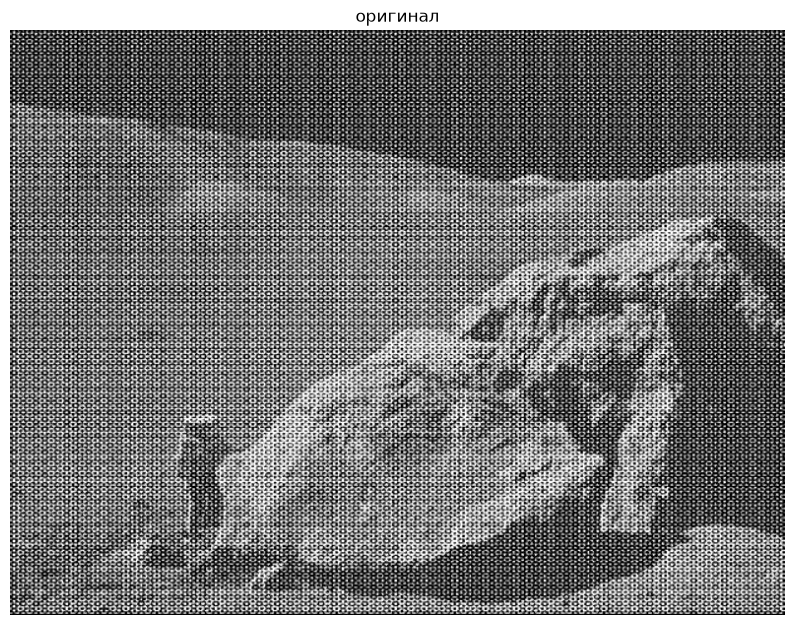

In [20]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
H, W = img.shape

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1)

f_ishift = np.fft.ifftshift(dft_shift)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0], img_back[:,:,1])

plt.figure(figsize=(10, 8))
plt.imshow(img, cmap='gray')
plt.title("оригинал")
plt.axis('off')
plt.show()

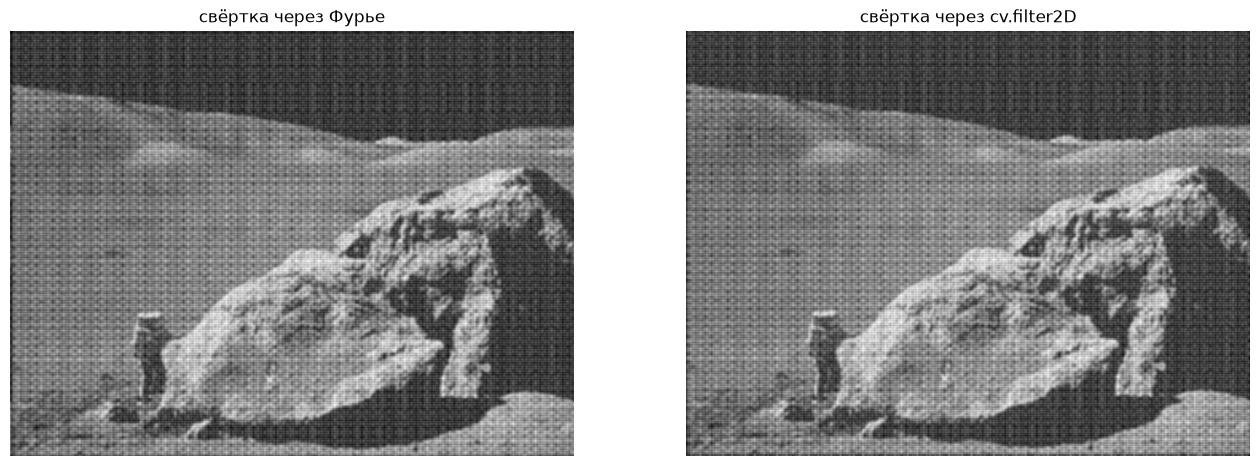

средняя разница между 2 методами: 16.584877829287


In [ ]:

kernel = np.ones((5, 5), np.float32) / 25

kernel_padded = np.zeros(img.shape, np.float32)
kernel_padded[:5, :5] = kernel

# свёртка через Фурье
img_fft = np.fft.fft2(img)
kernel_fft = np.fft.fft2(kernel_padded)
result_fft = img_fft * kernel_fft
result_spatial = np.real(np.fft.ifft2(result_fft))

# обычная свёртка через OpenCV
result_cv = cv.filter2D(img, -1, kernel)

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.imshow(result_spatial, cmap='gray')
plt.title("свёртка через Фурье")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(result_cv, cmap='gray')
plt.title("свёртка через cv.filter2D")
plt.axis('off')
plt.show()

# результаты почти одинаковые
diff = np.abs(result_spatial - result_cv).mean()
print("средняя разница между 2 методами:", diff)


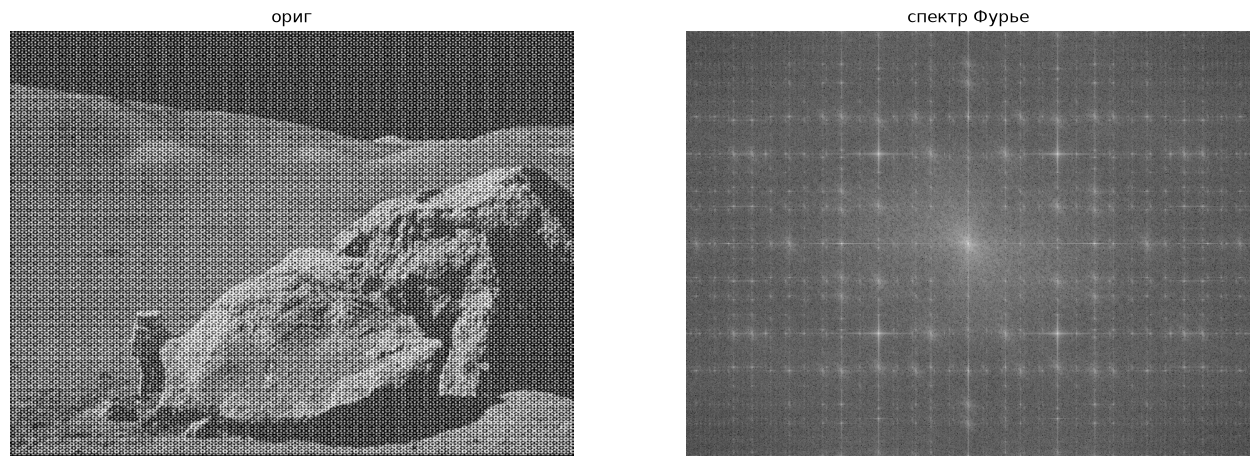

In [25]:
dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1)

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("ориг")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title("спектр Фурье")
plt.axis('off')
plt.show()

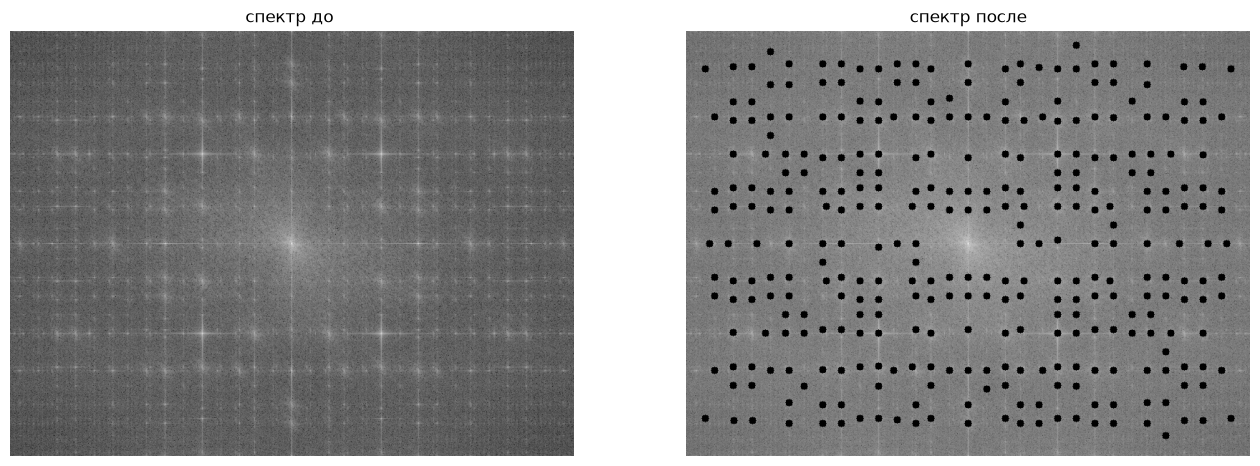

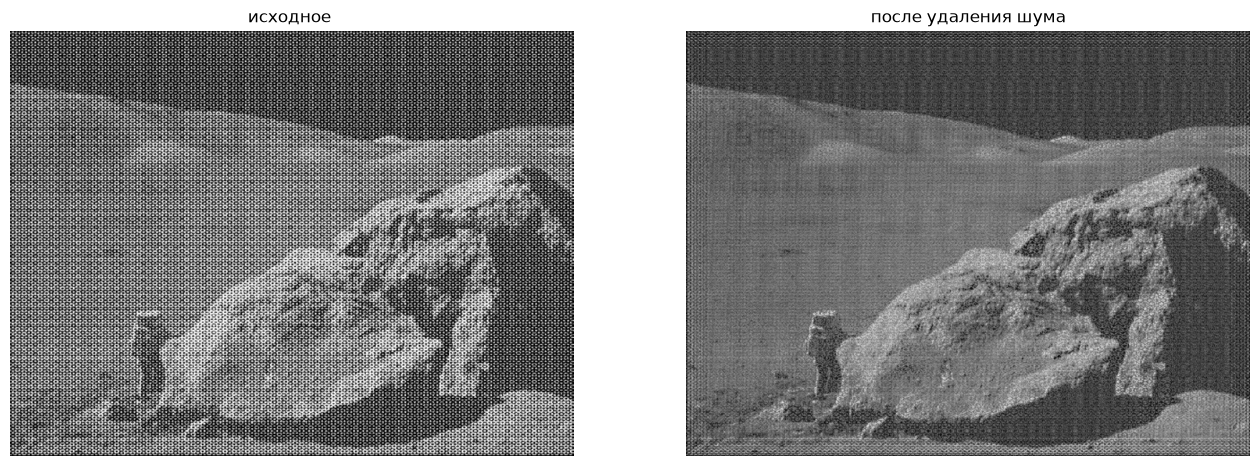

найдено пиков: 328


In [24]:
from skimage.feature import peak_local_max

# пересчитываю спектр
dft2 = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift2 = np.fft.fftshift(dft2)
magnitude_spectrum2 = 20 * np.log(cv.magnitude(dft_shift2[:, :, 0], dft_shift2[:, :, 1]) + 1)

# автомат нахожу лока макс(пики)
local_maxima = peak_local_max(magnitude_spectrum2, min_distance=20, threshold_abs=180)


mask = np.ones((rows, cols, 2), dtype=np.uint8)
for peak in local_maxima:
    y, x = peak

    distance = np.sqrt((x - ccol)**2 + (y - crow)**2)
    if distance > 40:
        cv.circle(mask, (x, y), 5, (0, 0), -1)


dft_shift_filtered = dft_shift2 * mask
magnitude_after = 20 * np.log(cv.magnitude(dft_shift_filtered[:, :, 0], dft_shift_filtered[:, :, 1]) + 1)

# обратное преобразование
f_ishift = np.fft.ifftshift(dft_shift_filtered)
img_clean = cv.idft(f_ishift)
img_clean = cv.magnitude(img_clean[:, :, 0], img_clean[:, :, 1])


plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.imshow(magnitude_spectrum2, cmap='gray')
plt.title(f"спектр до ")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(magnitude_after, cmap='gray')
plt.title("спектр после")
plt.axis('off')
plt.show()

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("исходное ")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_clean, cmap='gray')
plt.title("после удаления шума")
plt.axis('off')
plt.show()

print("найдено пиков:", len(local_maxima))